# **The Perspective (Pinhole) Camera Model**

A camera maps the 3D world onto a 2D image. The **perspective** (or **pinhole**) **camera model** describes this
mapping in two steps:

* the **extrinsic parameters** (the pose of the camera: a rotation and a translation) take a point from the
  **world** coordinate system to the **camera** coordinate system;
* the **intrinsic parameters** (focal length, pixel size, principal point) take it from camera coordinates to
  **pixel** coordinates in the image.

With homogeneous coordinates, the whole chain is a single $3 \times 4$ matrix, $P = K[R \mid \mathbf{t}]$. In this
notebook we derive the model, implement it with NumPy (and check it against OpenCV), and look at its geometric
consequences on a synthetic scene. Then we apply it to real data: a LiDAR scan and a photo of the ELTE campus,
recorded by a calibrated camera-LiDAR pair. We project the scan into the photo, color the 3D points with the photo,
and look at the colored scan from viewpoints where no camera has ever been.

## Table of Contents
1. Setup
2. Recap: Homogeneous Coordinates
3. The Pinhole Camera
4. Intrinsic Parameters: From the Image Plane to Pixels
5. Extrinsic Parameters: From the World to the Camera
6. The Projection Matrix $P = K[R \mid \mathbf{t}]$
7. Perspective Effects: Vanishing Points, Focal Length and Distance
8. A Real Camera: Projecting a LiDAR Scan into a Photo
9. A Virtual Camera: Viewing the Colored Scan from Anywhere
10. Summary

---

## 1. Setup

We use NumPy, OpenCV and Matplotlib. Images are displayed with Matplotlib, which works both in Google Colab
and in plain Jupyter. OpenCV stores color images as **BGR**, so `show_images` converts them to RGB before
plotting.

**Coordinate conventions.** We work with three coordinate systems:

- **Pixel coordinates** $(u, v)$: $u$ points to the right (column index), $v$ points **down** (row index), and the
  origin is the center of the top-left pixel. NumPy indexes images as `img[v, u]` (row first!), while OpenCV
  takes points as `(u, v)` and image sizes as `(width, height)`.
- **Camera coordinates** $(X_c, Y_c, Z_c)$, as in OpenCV: the origin is the projection center of the camera,
  $Z_c$ points forward along the optical axis, $X_c$ to the right and $Y_c$ **down**, parallel to $u$ and $v$.
  This is a right-handed system.
- **World coordinates** $(X_w, Y_w, Z_w)$: any right-handed system attached to the scene. In our synthetic
  scenes and in the LiDAR data, $Z_w$ points **up**.

In [ ]:
import os
import pickle
import urllib.request
import zipfile

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection

np.set_printoptions(precision=4, suppress=True)


def to_rgb(img):
    """OpenCV stores color images as BGR, Matplotlib expects RGB."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img


def show_images(images, titles=None, cols=None, size=3.5):
    """Show BGR (or grayscale) images side by side, with pixel coordinates on the axes."""
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    aspect = max(im.shape[0] / im.shape[1] for im in images)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * aspect * rows + 0.5 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for i, im in enumerate(images):
        ax = axes.ravel()[i]
        ax.axis('on')
        ax.imshow(to_rgb(im), cmap='gray' if im.ndim == 2 else None, interpolation='nearest')
        if titles is not None:
            ax.set_title(titles[i], fontsize=10)
    plt.tight_layout()
    plt.show()

The data for Sections 8 and 9 (a photo, a LiDAR scan and their calibration) is downloaded from the course
website if it is not there yet:

photo: width = 960, height = 600   (NumPy shape: (600, 960, 3))


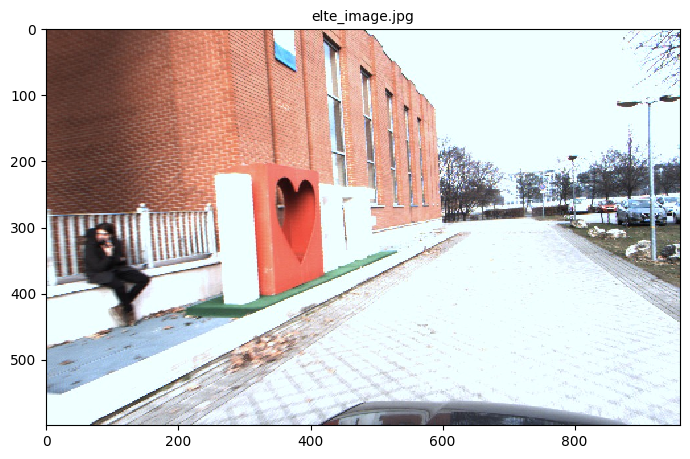

In [ ]:
DATA_URL = 'https://cv.inf.elte.hu/wp-content/uploads/2025/10/CalibratedData.zip'
DATA_DIR = 'data'
DATA_FILES = ['elte_image.jpg', 'elte_lidar.xyz', 'calib_data.pkl']

if not all(os.path.exists(os.path.join(DATA_DIR, name)) for name in DATA_FILES):
    zip_path, _ = urllib.request.urlretrieve(DATA_URL)        # download into a temporary file
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall('.')                               # creates data/ with the three files
    urllib.request.urlcleanup()                               # delete the temporary file

photo = cv2.imread(os.path.join(DATA_DIR, 'elte_image.jpg'))
print(f'photo: width = {photo.shape[1]}, height = {photo.shape[0]}   (NumPy shape: {photo.shape})')
show_images([photo], ['elte_image.jpg'], size=7)

---
## 2. Recap: Homogeneous Coordinates

In the previous classes we described 2D transformations with $3 \times 3$ matrices acting on **homogeneous
coordinates**:

- A point $(x, y)$ is written as $(x, y, 1)$. A homogeneous vector $(x_1, x_2, x_3)$ with $x_3 \neq 0$ represents the
  point $(x_1 / x_3, x_2 / x_3)$, so $\mathbf{x}$ and $\lambda\mathbf{x}$ are the **same** point for any $\lambda \neq 0$.
  Going back to ordinary coordinates is the **perspective division**.
- $(d_x, d_y, 0)$ is a **point at infinity**: the direction $(d_x, d_y)$, where all lines with this direction meet.
- A $3 \times 3$ matrix with a general last row is a **homography**. Its third output coordinate varies across the
  image, and the division by it creates perspective: vanishing points and a horizon.
- A camera looking at a **plane** maps it to the image with the homography $H = K[\mathbf{r}_1 \;\, \mathbf{r}_2 \;\, \mathbf{t}]$,
  and the third coordinate is the **depth**.

Today we drop the restriction to a plane. The same rules hold one dimension higher: a 3D point $(X, Y, Z)$ is
$(X, Y, Z, 1)$, and $(X, Y, Z, 0)$ is a direction in space (a point at infinity). A camera will be a $3 \times 4$
matrix that maps homogeneous 3D points to homogeneous 2D points.

Below are two small helpers that work in any dimension. Point sets are stored as $N \times d$ arrays, **one point per row**
(like the LiDAR file in Section 8), so a matrix $M$ is applied to all of them as `pts @ M.T`.

In [ ]:
def to_homogeneous(pts):
    """(N, d) array of points -> (N, d+1) array: append a 1 to every point."""
    pts = np.asarray(pts, dtype=float)
    return np.hstack([pts, np.ones((len(pts), 1))])


def from_homogeneous(pts_h):
    """(N, d+1) array of homogeneous points -> (N, d) array: the perspective division."""
    pts_h = np.asarray(pts_h, dtype=float)
    return pts_h[:, :-1] / pts_h[:, -1:]


print('2D point (2, 3)        ->', to_homogeneous([[2, 3]]))
print('homogeneous (4, 6, 2)  ->', from_homogeneous([[4, 6, 2]]), '  the same point')
print('3D point (1, 2, 5)     ->', to_homogeneous([[1, 2, 5]]))

2D point (2, 3)        -> [[2. 3. 1.]]
homogeneous (4, 6, 2)  -> [[2. 3.]]   the same point
3D point (1, 2, 5)     -> [[1. 2. 5. 1.]]


---
## 3. The Pinhole Camera

### 3.1 Central projection
A *camera obscura* is a dark box with a tiny hole in one wall. Every scene point sends exactly one ray through
the hole, and the ray hits the back wall at distance $f$ behind it, so the back wall shows an **inverted** image
of the scene. It is more convenient to put the image plane at the same distance $f$ **in front of** the hole:
the same rays cross it, and the image there is upright. This is the **pinhole** (or **perspective**) camera.
The hole is the **projection center** (optical center), and the line through it perpendicular to the image plane
is the **optical axis**.

In camera coordinates, the projection center is the origin and the optical axis is the $Z_c$ axis. The ray from
a point $(X_c, Y_c, Z_c)$ through the origin crosses the image plane $Z_c = f$ at $(x, y, f)$, and by similar
triangles
$$
\frac{x}{f} = \frac{X_c}{Z_c}, \quad \frac{y}{f} = \frac{Y_c}{Z_c}
\qquad\Longrightarrow\qquad
x = f\,\frac{X_c}{Z_c}, \quad y = f\,\frac{Y_c}{Z_c}.
$$
The inverted image on the back wall is at $(-x, -y)$. The figure shows the $Y_c Z_c$ plane from the side: a camera
$1.2$ units above the ground looks horizontally at two trees of equal height, the second one twice as far as
the first. ($Y_c$ points down, as in the camera coordinate system.)

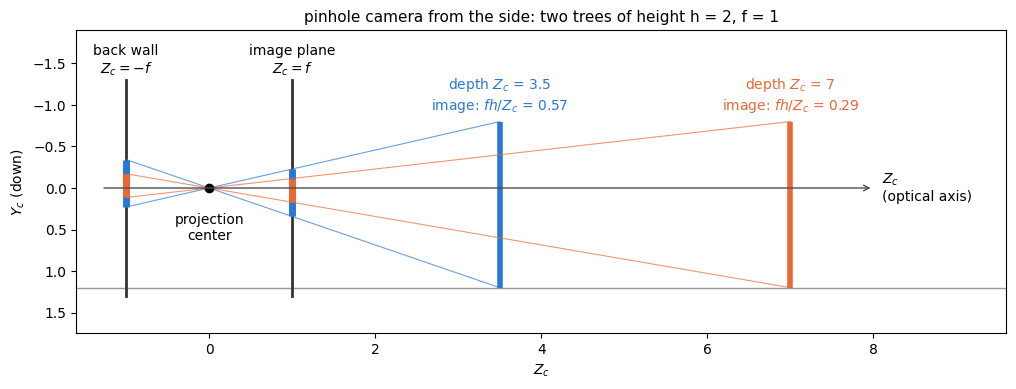

In [ ]:
def pinhole_side_view(f=1.0, cam_height=1.2, tree_height=2.0, depths=(3.5, 7.0)):
    """Side view (the Y_c Z_c plane) of a pinhole camera looking at equal trees at different depths."""
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.axhline(cam_height, color='0.6', lw=1)                         # the ground (Y_c points down)
    ax.annotate('', xy=(depths[-1] + 1.0, 0), xytext=(-f - 0.3, 0),
                arrowprops=dict(arrowstyle='->', color='0.3', lw=1))  # the optical axis
    ax.text(depths[-1] + 1.1, 0, '$Z_c$\n(optical axis)', fontsize=10, va='center')
    for z, label in [(f, 'image plane\n$Z_c = f$'), (-f, 'back wall\n$Z_c = -f$')]:
        ax.plot([z, z], [-1.3, 1.3], color='0.2', lw=2)
        ax.text(z, -1.38, label, ha='center', fontsize=10)
    for z, color in zip(depths, ['#2a78d6', '#eb6834']):
        ends = np.array([[z, cam_height], [z, cam_height - tree_height]])   # (Z_c, Y_c) of the foot and the top
        ax.plot(*ends.T, color=color, lw=4, solid_capstyle='butt')
        for Z, Y in ends:
            ax.plot([-f, Z], [-f * Y / Z, Y], color=color, lw=0.8, alpha=0.7)   # the ray through the center
        for zi in (f, -f):                                                  # the two images of the tree
            ax.plot([zi, zi], zi * ends[:, 1] / ends[:, 0], color=color, lw=5, solid_capstyle='butt')
        ax.text(z, cam_height - tree_height - 0.08, f'depth $Z_c$ = {z:g}\nimage: $f h / Z_c$ = {f * tree_height / z:.2f}',
                color=color, fontsize=10, ha='center', va='bottom')
    ax.plot(0, 0, 'ko', ms=6)
    ax.text(0, 0.3, 'projection\ncenter', ha='center', va='top', fontsize=10)
    ax.set_xlim(-f - 0.6, depths[-1] + 2.6)
    ax.set_ylim(1.75, -1.9)                                           # Y_c points down
    ax.set_aspect('equal')
    ax.set_xlabel('$Z_c$')
    ax.set_ylabel('$Y_c$ (down)')
    ax.set_title(f'pinhole camera from the side: two trees of height h = {tree_height:g}, f = {f:g}', fontsize=11)
    plt.show()


pinhole_side_view()

Two consequences:
- **The image size is inversely proportional to the depth.** An object of height $h$ at depth $Z_c$ has an image of
  height $f h / Z_c$. The orange tree is twice as far as the blue one, so its image is half as tall.
- **Depth is lost.** All points of a ray through the projection center have the same image, so a single image
  does not tell how far a point is. Recovering depth needs more information: a second camera (stereo, as in the
  first class), the known size of an object, or a known plane, such as the ground.

### 3.2 The projection as a matrix
The division by $Z_c$ is exactly the perspective division of homogeneous coordinates:
$$
\begin{bmatrix} f X_c \\ f Y_c \\ Z_c \end{bmatrix}
= \begin{bmatrix} f & 0 & 0 & 0 \\ 0 & f & 0 & 0 \\ 0 & 0 & 1 & 0 \end{bmatrix}
  \begin{bmatrix} X_c \\ Y_c \\ Z_c \\ 1 \end{bmatrix}
\;\sim\;
\begin{bmatrix} f X_c / Z_c \\ f Y_c / Z_c \\ 1 \end{bmatrix}.
$$
- The map is **linear in homogeneous coordinates**. All of the non-linearity is in the final division.
- The third homogeneous coordinate is the **depth** $Z_c$.
- Points with $Z_c = 0$ (in the plane through the projection center parallel to the image plane) are mapped to
  infinity.
- Points **behind** the camera ($Z_c < 0$) are projected too. The point mirrored through the projection center,
  $-\mathbf{X}_c$, gives $-(f X_c, f Y_c, Z_c)$, which is the **same** image point as that of $\mathbf{X}_c$. A real camera
  cannot see points behind it, so **we always have to check $Z_c > 0$ ourselves**.

In [ ]:
f = 1.0
P0 = np.array([[f, 0, 0, 0],
               [0, f, 0, 0],
               [0, 0, 1, 0]])

X_c = np.array([[1.0, -0.5, 4.0],      # a point
                [2.0, -1.0, 8.0],      # on the same ray, twice as far
                [1.0, -0.5, 8.0],      # the same X_c and Y_c, twice as far
                [-1.0, 0.5, -4.0]])    # the first point mirrored through the projection center: behind the camera
x_h = to_homogeneous(X_c) @ P0.T      # one homogeneous image point per row
for X, xh, xy in zip(X_c, x_h, from_homogeneous(x_h)):
    print(f'X_c = {X}  ->  homogeneous {xh}  ->  image point {xy}')

X_c = [ 1.  -0.5  4. ]  ->  homogeneous [ 1.  -0.5  4. ]  ->  image point [ 0.25  -0.125]
X_c = [ 2. -1.  8.]  ->  homogeneous [ 2. -1.  8.]  ->  image point [ 0.25  -0.125]
X_c = [ 1.  -0.5  8. ]  ->  homogeneous [ 1.  -0.5  8. ]  ->  image point [ 0.125  -0.0625]
X_c = [-1.   0.5 -4. ]  ->  homogeneous [-1.   0.5 -4. ]  ->  image point [ 0.25  -0.125]


The first, second and fourth points have the same image point. Only the third homogeneous coordinate, the depth,
reveals that the fourth one is behind the camera.

---

## 4. Intrinsic Parameters: From the Image Plane to Pixels

The coordinates $(x, y)$ above are metric (e.g., millimeters on the sensor) and are measured from the point where
the optical axis pierces the image plane, the **principal point**. The sensor, however, measures in **pixels**,
counted from the top-left pixel. Let $k_u$ and $k_v$ be the number of pixels per unit length in the two directions (the
reciprocals of the pixel width and height), and $(u_0, v_0)$ the pixel coordinates of the principal point. Then
$$
u = k_u\, x + u_0 = f k_u \frac{X_c}{Z_c} + u_0, \qquad v = k_v\, y + v_0 = f k_v \frac{Y_c}{Z_c} + v_0,
$$
or, in matrix form,
$$
Z_c \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \begin{bmatrix} X_c \\ Y_c \\ Z_c \end{bmatrix},
\qquad
K = \begin{bmatrix} f k_u & s & u_0 \\ 0 & f k_v & v_0 \\ 0 & 0 & 1 \end{bmatrix}
  = \begin{bmatrix} f_x & s & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}.
$$
$K$ is the **camera matrix** (or calibration matrix). This upper triangular matrix contains the **intrinsic parameters**:
- $f_x = f k_u$ and $f_y = f k_v$: the focal length **measured in pixels**. Only these products matter: from images
  alone, a twice as long focal length cannot be distinguished from twice as dense pixels. For square pixels,
  $f_x = f_y$.
- $(c_x, c_y) = (u_0, v_0)$: the principal point, usually close to the center of the image.
- $s$: the **skew**, non-zero only if the axes of the pixel grid are not perpendicular. It is $0$ for practically
  every modern sensor, and OpenCV does not even model it.

So $K$ has 5 degrees of freedom, 4 without skew. OpenCV calls it `cameraMatrix` and its entries `fx, fy, cx, cy`.

**Field of view.** The image spans $W$ pixels horizontally, $W/2$ on each side of the principal point (if it is in
the center), so the horizontal field of view is $2 \arctan\frac{W}{2 f_x}$, and the vertical one is $2 \arctan\frac{H}{2 f_y}$.

As an example, we build $K$ for the Raspberry Pi Camera Module v2 from its data sheet: a $3.04$ mm lens and a
$3280 \times 2464$ sensor with $1.12\,\mu$m pixels. `cv2.calibrationMatrixValues` computes the field of view (and the
focal length in mm, if we give it the physical size of the sensor) from $K$:

In [ ]:
f_mm = 3.04                      # focal length of the lens
pixel_mm = 1.12e-3               # pixel size (1.12 um), so k_u = k_v = 1 / pixel_mm pixels per mm
W_pi, H_pi = 3280, 2464          # resolution of the sensor

f_px = f_mm / pixel_mm           # f * k_u: the focal length in pixels
K_pi = np.array([[f_px, 0, (W_pi - 1) / 2],      # principal point: the center of the image
                 [0, f_px, (H_pi - 1) / 2],      # (pixel centers are at integer coordinates)
                 [0, 0, 1]])
print('K =\n', K_pi)

fov_x = np.degrees(2 * np.arctan(W_pi / (2 * f_px)))
fov_y = np.degrees(2 * np.arctan(H_pi / (2 * f_px)))
fov_x_cv, fov_y_cv, f_mm_cv, _, _ = cv2.calibrationMatrixValues(K_pi, (W_pi, H_pi), W_pi * pixel_mm, H_pi * pixel_mm)
print(f'field of view, NumPy:  {fov_x:.2f} x {fov_y:.2f} degrees')
print(f'field of view, OpenCV: {fov_x_cv:.2f} x {fov_y_cv:.2f} degrees   (data sheet: 62.2 x 48.8)')
print(f'focal length recovered by OpenCV from K and the sensor size: {f_mm_cv:.2f} mm')

K =
 [[2714.2857    0.     1639.5   ]
 [   0.     2714.2857 1231.5   ]
 [   0.        0.        1.    ]]
field of view, NumPy:  62.28 x 48.83 degrees
field of view, OpenCV: 62.28 x 48.83 degrees   (data sheet: 62.2 x 48.8)
focal length recovered by OpenCV from K and the sensor size: 3.04 mm


### 4.1 Back-projection: from a pixel to a ray
$K$ is invertible, so a pixel determines the **direction** of its ray:
$$
\mathbf{X}_c = \lambda\, K^{-1} \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}, \qquad \lambda > 0.
$$
The third coordinate of $K^{-1}(u, v, 1)^\top$ is $1$, so $\lambda$ is the depth $Z_c$, which the image does not tell us.
The first two coordinates are the **normalized image coordinates**: what an ideal camera with $f = 1$ and the
principal point at the origin would see. OpenCV computes them with `cv2.undistortPoints` (which also removes the
lens distortion, see below). As a check, the angle between the rays through the left and the right border of
the image is the horizontal field of view.

In [ ]:
def backproject(K, uv):
    """Rays through the pixels uv (N, 2), in camera coordinates: the rows of K^-1 (u, v, 1), which have Z_c = 1."""
    return to_homogeneous(uv) @ np.linalg.inv(K).T


borders = np.array([[-0.5, (H_pi - 1) / 2],            # the middle of the left border of the image ...
                    [W_pi - 0.5, (H_pi - 1) / 2]])     # ... and of the right border
rays = backproject(K_pi, borders)
angle = np.degrees(np.arccos(rays[0] @ rays[1] / (np.linalg.norm(rays[0]) * np.linalg.norm(rays[1]))))
print('rays through the left and right border:\n', rays)
print(f'angle between them: {angle:.2f} degrees, the horizontal field of view')

normalized_cv = cv2.undistortPoints(borders.reshape(-1, 1, 2), K_pi, None).reshape(-1, 2)
print('cv2.undistortPoints gives the same normalized coordinates:', np.allclose(normalized_cv, rays[:, :2]))

rays through the left and right border:
 [[-0.6042  0.      1.    ]
 [ 0.6042  0.      1.    ]]
angle between them: 62.28 degrees, the horizontal field of view
cv2.undistortPoints gives the same normalized coordinates: True


**Lens distortion.** Real lenses, especially wide-angle ones, deviate from the pinhole model: straight lines bend
near the border of the image (radial distortion). OpenCV models this with a few extra coefficients (`distCoeffs`),
a non-linear correction applied between the division by $Z_c$ and the multiplication by $K$. Estimating them is
part of camera calibration, a topic of a later class. In this notebook we use the ideal pinhole model
(`distCoeffs = None`).

---

## 5. Extrinsic Parameters: From the World to the Camera

The points of a scene are usually given in a **world** coordinate system that has nothing to do with the camera:
the coordinate system of a room, of a map, or of another sensor (in Section 8, a LiDAR). The camera is placed at
a point $\mathbf{C}$ of the world (the **camera center**, i.e. the projection center), and it is rotated. The
change from world to camera coordinates is a rigid transformation:
$$
\mathbf{X}_c = R\,(\mathbf{X}_w - \mathbf{C}) = R\,\mathbf{X}_w + \mathbf{t},
\qquad \text{where} \qquad \mathbf{t} = -R\,\mathbf{C}, \quad \mathbf{C} = -R^\top \mathbf{t}.
$$
- $\mathbf{X}_w - \mathbf{C}$ is the vector from the camera center to the point, and multiplying it by $R$ expresses
  it in the camera's axes. The **rows** $\mathbf{r}_1^\top, \mathbf{r}_2^\top, \mathbf{r}_3^\top$ of $R$ are the camera's $X_c$ (right),
  $Y_c$ (down) and $Z_c$ (viewing direction) axes, written in world coordinates. For example, the depth of a point,
  $Z_c = \mathbf{r}_3^\top(\mathbf{X}_w - \mathbf{C})$, is its distance from the camera center along the viewing direction.
- $R$ is a rotation matrix ($R^\top R = I$, $\det R = +1$) with 3 degrees of freedom, and $\mathbf{C}$ (or $\mathbf{t}$)
  adds 3 more: the 6 **extrinsic parameters**, or the **pose** of the camera.
- **Careful with $\mathbf{t}$.** It is *not* the position of the camera, but the position of the world origin in
  camera coordinates. Both forms are in use: OpenCV (and the calibration file of Section 8) use
  $R\mathbf{X}_w + \mathbf{t}$, while $R(\mathbf{X}_w - \mathbf{C})$ is more natural when we place a camera ourselves.
  Some texts write the latter with the letter $\mathbf{t}$ for the camera position, so always check which one is
  meant.

In homogeneous coordinates, both forms are a single matrix product:
$$
\mathbf{X}_c = [R \mid \mathbf{t}] \begin{bmatrix} \mathbf{X}_w \\ 1 \end{bmatrix}
= R\,[I \mid -\mathbf{C}] \begin{bmatrix} \mathbf{X}_w \\ 1 \end{bmatrix},
\qquad\text{or, as a } 4 \times 4 \text{ matrix,}\qquad
\begin{bmatrix} \mathbf{X}_c \\ 1 \end{bmatrix} = \begin{bmatrix} R & \mathbf{t} \\ \mathbf{0}^\top & 1 \end{bmatrix}
\begin{bmatrix} \mathbf{X}_w \\ 1 \end{bmatrix}.
$$

### 5.1 Rotation vectors
A rotation matrix has 9 entries but only 3 degrees of freedom. OpenCV often uses the **rotation vector** (the
axis-angle form) $\mathbf{r} = \theta\,\mathbf{k}$: a rotation by the angle $\theta = \lVert\mathbf{r}\rVert$ about the unit
axis $\mathbf{k}$. **Rodrigues' formula** turns it into a matrix:
$$
R = I + \sin\theta\, [\mathbf{k}]_\times + (1 - \cos\theta)\, [\mathbf{k}]_\times^2,
\qquad
[\mathbf{k}]_\times = \begin{bmatrix} 0 & -k_z & k_y \\ k_z & 0 & -k_x \\ -k_y & k_x & 0 \end{bmatrix},
$$
where $[\mathbf{k}]_\times \mathbf{v} = \mathbf{k} \times \mathbf{v}$ is the cross product as a matrix. `cv2.Rodrigues` converts in
both directions. `cv2.projectPoints` (Section 6) and `cv2.solvePnP` (camera pose estimation, in a later class)
expect rotation vectors.

In [ ]:
def cross_matrix(k):
    """The matrix [k]_x with cross_matrix(k) @ v == np.cross(k, v)."""
    return np.array([[0, -k[2], k[1]],
                     [k[2], 0, -k[0]],
                     [-k[1], k[0], 0]])


def rodrigues(rvec):
    """Rotation matrix of the rotation vector rvec (axis * angle in radians), with Rodrigues' formula."""
    rvec = np.asarray(rvec, dtype=float)
    theta = np.linalg.norm(rvec)
    if theta < 1e-12:
        return np.eye(3)
    k = cross_matrix(rvec / theta)
    return np.eye(3) + np.sin(theta) * k + (1 - np.cos(theta)) * k @ k


rvec = np.array([0.2, -0.5, 0.3])
R_np = rodrigues(rvec)
R_cv, _ = cv2.Rodrigues(rvec)
print('R =\n', R_np)
print('cv2.Rodrigues gives the same matrix:', np.allclose(R_np, R_cv))
print('R^T R = I:', np.allclose(R_np.T @ R_np, np.eye(3)), f'  det R = {np.linalg.det(R_np):.6f}')
print('back to the rotation vector with cv2.Rodrigues:', cv2.Rodrigues(R_np)[0].ravel())

R =
 [[ 0.8353 -0.3298 -0.4399]
 [ 0.2329  0.937  -0.2602]
 [ 0.498   0.1149  0.8595]]
cv2.Rodrigues gives the same matrix: True
R^T R = I: True   det R = 1.000000
back to the rotation vector with cv2.Rodrigues: [ 0.2 -0.5  0.3]


### 5.2 Placing a camera: look-at
To place a virtual camera, we choose its position $\mathbf{C}$ (the "eye"), a target point $\mathbf{T}$ to look at, and
the world direction $\mathbf{up}$ that should point upwards in the image. The rows of $R$ follow directly:
$$
\mathbf{r}_3 = \frac{\mathbf{T} - \mathbf{C}}{\lVert \mathbf{T} - \mathbf{C} \rVert}, \qquad
\mathbf{r}_1 = \frac{\mathbf{r}_3 \times \mathbf{up}}{\lVert \mathbf{r}_3 \times \mathbf{up} \rVert}, \qquad
\mathbf{r}_2 = \mathbf{r}_3 \times \mathbf{r}_1.
$$
$\mathbf{r}_1$ (right) is perpendicular to $\mathbf{up}$, i.e. horizontal, so the image is not tilted sideways, and
$\mathbf{r}_2$ (down) is perpendicular to both. This order of the cross products makes the camera system right-handed,
so $\det R = +1$. (It fails only if the camera looks exactly along $\mathbf{up}$.)

An **orbit camera** moves on a sphere around the target and always looks at it. Its position is given by an
azimuth (the angle from the $X_w$ axis in the horizontal plane), an elevation (the angle above the horizontal
plane) and a distance. We will use it in Section 9 to fly around the LiDAR scan.

In [ ]:
def look_at(eye, target, up=(0, 0, 1)):
    """Rotation R and translation t (X_c = R X_w + t) of a camera at `eye` that looks at `target`.
    `up` is the world direction that should point upwards in the image."""
    eye, target, up = (np.asarray(a, dtype=float) for a in (eye, target, up))
    z = target - eye
    z /= np.linalg.norm(z)                      # viewing direction
    x = np.cross(z, up)
    x /= np.linalg.norm(x)                      # right (horizontal)
    y = np.cross(z, x)                          # down
    R = np.stack([x, y, z])                     # the rows of R are the camera axes in world coordinates
    return R, -R @ eye                          # t = -R C


def orbit_camera(azimuth_deg, elevation_deg, distance, target=(0, 0, 0)):
    """Camera on a sphere around `target`, looking at it. The angles are in degrees."""
    a, e = np.deg2rad(azimuth_deg), np.deg2rad(elevation_deg)
    eye = np.asarray(target, dtype=float) + distance * np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])
    return look_at(eye, target)


R_test, t_test = orbit_camera(-60, 20, 7, target=(0, 0, 1))
print('R =\n', R_test)
print('R^T R = I:', np.allclose(R_test.T @ R_test, np.eye(3)), f'  det R = {np.linalg.det(R_test):.6f}')
print('camera center C = -R^T t =', -R_test.T @ t_test)

R =
 [[ 0.866   0.5    -0.    ]
 [ 0.171  -0.2962 -0.9397]
 [-0.4698  0.8138 -0.342 ]]
R^T R = I: True   det R = 1.000000
camera center C = -R^T t = [ 3.2889 -5.6966  3.3941]


To see some cameras, we need a scene. Our synthetic scenes are made of straight segments, stored as arrays of
shape $(E, 2, 3)$: $E$ segments, 2 endpoints, 3 coordinates. `house` builds a wireframe house, and `camera_frustum`
the viewing pyramid of a camera: the rays through the four corners of the image (back-projected with $K^{-1}$ and
turned into world coordinates with $\mathbf{X}_w = \mathbf{C} + R^\top \mathbf{X}_c$), cut at a given depth.

In [ ]:
def box_edges(x0, y0, z0, x1, y1, z1):
    """The 12 edges of the axis-aligned box [x0, x1] x [y0, y1] x [z0, z1], as a (12, 2, 3) array."""
    corners = np.array([[x, y, z] for z in (z0, z1) for y in (y0, y1) for x in (x0, x1)], dtype=float)
    pairs = [(0, 1), (2, 3), (4, 5), (6, 7),    # edges along x
             (0, 2), (1, 3), (4, 6), (5, 7),    # along y
             (0, 4), (1, 5), (2, 6), (3, 7)]    # along z
    return corners[np.array(pairs)]


def house(x, y, w=2.0, d=2.0, h=1.5, roof=1.0):
    """Wireframe of a w x d x h house standing on the ground at (x, y), with a gable roof of height `roof`."""
    xm, top = x + w / 2, h + roof
    ridge = [[[xm, y, top], [xm, y + d, top]]]
    slopes = [[[xx, yy, h], [xm, yy, top]] for xx in (x, x + w) for yy in (y, y + d)]
    return np.concatenate([box_edges(x, y, 0, x + w, y + d, h), np.array(ridge + slopes, dtype=float)])


def camera_frustum(K, R, t, size, depth=1.0):
    """The viewing pyramid of a camera with image size (width, height), cut at `depth`: (8, 2, 3) world segments."""
    w, h = size
    C = -R.T @ t
    corners = np.array([[-0.5, -0.5], [w - 0.5, -0.5], [w - 0.5, h - 0.5], [-0.5, h - 0.5]])   # image corners
    far = C + depth * backproject(K, corners) @ R          # X_w = C + R^T X_c, for every row
    return np.array([[C, p] for p in far] + [[far[i], far[(i + 1) % 4]] for i in range(4)])

Below, a house and an **orbit camera** that looks at the point $\mathbf{T} = (0, 0, 1)$ above the center of the house.
Use the sliders to change the azimuth, the elevation and the distance of the camera. The camera is drawn with its
viewing pyramid and its axes: $X_c$ red, $Y_c$ green, $Z_c$ blue, i.e. the rows of its $R$ (printed below the figure).
The dotted lines are the paths of the camera on its sphere: the horizontal circle when only the azimuth changes, the
vertical arc when only the elevation changes. Changing the distance moves it along the dashed line to $\mathbf{T}$.

Note that $X_c$ always stays horizontal (the last entry of $\mathbf{r}_1$ is 0) and $Y_c$ points downwards, even when the
camera looks almost straight down. At elevation $90^\circ$, `look_at` would fail, so the slider stops at $89^\circ$.
(Without `ipywidgets`, the cell draws a single view.)

In [ ]:
AXIS_COLORS = ['#e34948', '#008300', '#2a78d6']        # x, y, z axes: red, green, blue

K_demo = np.array([[500, 0, 319.5],
                   [0, 500, 239.5],
                   [0, 0, 1]])
size_demo = (640, 480)                                   # (width, height)
house_demo = house(-1, -1)                               # a 2 x 2 house around the origin, roof up to 2.5
target_demo = np.array([0, 0, 1.0])                      # the orbit cameras look at this point
ground_grid = np.array([seg for k in range(-8, 9, 2)     # a grid on the ground, as (E, 2, 3) segments
                        for seg in ([[k, -8, 0], [k, 8, 0]], [[-8, k, 0], [8, k, 0]])], dtype=float)
world_axes = np.array([[np.zeros(3), 1.5 * e] for e in np.eye(3)])     # X_w, Y_w, Z_w, 1.5 long


def draw_orbit_scene(ax, azimuth, elevation, distance):
    """Draw the house and an orbit camera around target_demo into the 3D axis `ax`: the viewing pyramid and
    the axes of the camera, and its paths on the sphere. Returns R and t of the camera."""
    R, t = orbit_camera(azimuth, elevation, distance, target=target_demo)
    C = -R.T @ t
    a, e = np.deg2rad(azimuth), np.deg2rad(elevation)
    s = np.linspace(0, 2 * np.pi, 145)                   # azimuths for the horizontal circle
    latitude = target_demo + distance * np.stack([np.cos(e) * np.cos(s), np.cos(e) * np.sin(s), np.full_like(s, np.sin(e))], axis=1)
    s = np.linspace(min(e, 0), np.pi / 2, 37)            # elevations for the vertical arc, up to the pole
    meridian = target_demo + distance * np.stack([np.cos(s) * np.cos(a), np.cos(s) * np.sin(a), np.sin(s)], axis=1)

    for seg in ground_grid:
        ax.plot(*seg.T, color='0.88', lw=0.8)
    ax.add_collection3d(Line3DCollection(house_demo, colors='#eb6834', lw=1.5))
    for i, (origin, tip) in enumerate(world_axes):
        ax.quiver(*origin, *(tip - origin), color=AXIS_COLORS[i], lw=2.5, arrow_length_ratio=0.15)
    ax.plot(*latitude.T, ':', color='0.45', lw=1)        # azimuth changes: a horizontal circle
    ax.plot(*meridian.T, ':', color='0.45', lw=1)        # elevation changes: a vertical arc
    ax.plot(*np.stack([target_demo, C]).T, '--', color='0.45', lw=1)    # distance changes: along the radius
    ax.scatter(*target_demo, color='k', s=15)
    ax.text(*(target_demo + [0.25, 0, -0.1]), r'$\mathbf{T}$', fontsize=10)
    ax.add_collection3d(Line3DCollection(camera_frustum(K_demo, R, t, size_demo, depth=1.5), colors='0.3', lw=1))
    for i in range(3):                                   # row i of R = camera axis i
        ax.quiver(*C, *R[i], color=AXIS_COLORS[i], lw=2, arrow_length_ratio=0.2)
    ax.text(*(C + [0, 0, 0.5]), 'camera', fontsize=10)
    ax.set_xlim(-8, 8)
    ax.set_ylim(-8, 8)
    ax.set_zlim(-1, 9.5)
    ax.set_box_aspect((16, 16, 10.5), zoom=1.2)
    ax.set_xlabel('$X_w$')
    ax.set_ylabel('$Y_w$')
    ax.set_zlabel('$Z_w$')
    ax.set_title(f'azimuth {azimuth:.0f}°, elevation {elevation:.0f}°, distance {distance:.1f}', fontsize=10)
    ax.view_init(elev=24, azim=-105)
    return R, t


def show_orbit_camera(azimuth=-60.0, elevation=20.0, distance=7.0):
    """3D view of the house and of an orbit camera around target_demo. Prints the camera center and R."""
    fig = plt.figure(figsize=(9, 8))
    R, t = draw_orbit_scene(fig.add_subplot(projection='3d'), azimuth, elevation, distance)
    plt.tight_layout()
    plt.show()
    print('camera center C =', -R.T @ t)
    print('R (rows: X_c, Y_c, Z_c in world coordinates) =\n', R)

In [ ]:
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    interact = None
    print('ipywidgets is not installed (pip install ipywidgets), showing a single view.')

if interact is not None:
    interact(show_orbit_camera,
             azimuth=FloatSlider(min=-180, max=180, step=5, value=-60),
             elevation=FloatSlider(min=-10, max=89, step=1, value=20),
             distance=FloatSlider(min=3, max=8, step=0.5, value=7))
else:
    show_orbit_camera()

interactive(children=(FloatSlider(value=-60.0, description='azimuth', max=180.0, min=-180.0, step=5.0), FloatS…

Section 6 refers to three fixed orbit cameras. To see one of them in 3D, set the sliders above to its values.

In [ ]:
orbits = [(-60, 20, 7), (20, 35, 7), (150, 10, 6)]       # (azimuth, elevation, distance)
cameras = [orbit_camera(a, e, d, target=target_demo) for a, e, d in orbits]
for k, ((a, e, d), (R, t)) in enumerate(zip(orbits, cameras)):
    print(f'camera {k + 1}: azimuth {a:4d}°, elevation {e:2d}°, distance {d},  center C = {-R.T @ t}')

camera 1: azimuth  -60°, elevation 20°, distance 7,  center C = [ 3.2889 -5.6966  3.3941]
camera 2: azimuth   20°, elevation 35°, distance 7,  center C = [5.3883 1.9612 5.015 ]
camera 3: azimuth  150°, elevation 10°, distance 6,  center C = [-5.1172  2.9544  2.0419]


---
## 6. The Projection Matrix $P = K[R \mid \mathbf{t}]$

Putting the two steps together, a world point $\mathbf{X}_w$ is mapped to the pixel $(u, v)$ by
$$
\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}
= K\,[R \mid \mathbf{t}] \begin{bmatrix} \mathbf{X}_w \\ 1 \end{bmatrix}
= P \begin{bmatrix} \mathbf{X}_w \\ 1 \end{bmatrix},
\qquad P = K\,[R \mid \mathbf{t}] = K R\,[I \mid -\mathbf{C}],
$$
where $\lambda = Z_c$ is the depth of the point.
- $P$ is a $3 \times 4$ matrix. Like a homography, it is defined only up to scale, so it has $12 - 1 = 11$ degrees of
  freedom: $5$ intrinsic ($K$) and $6$ extrinsic ($R$ and $\mathbf{t}$).
- The camera center is the only point without an image: $P\,(\mathbf{C}, 1)^\top = K R\,(\mathbf{C} - \mathbf{C}) = \mathbf{0}$.
  So $(\mathbf{C}, 1)$ spans the **null space** of $P$, and the camera center can be read off from any projection
  matrix, for example with an SVD.
- A direction $\mathbf{d}$, i.e. the point at infinity $(\mathbf{d}, 0)$, is mapped to $K R\,\mathbf{d}$, independently of the
  position of the camera. This is the **vanishing point** of the direction (Section 7).
- The projection is linear in homogeneous coordinates, so **straight lines are mapped to straight lines**.

### 6.1 Implementation
`project_points` returns the depths as well, so that the caller can discard the points behind the camera.

In [ ]:
def projection_matrix(K, R, t):
    """P = K [R | t], the 3x4 camera matrix."""
    return K @ np.hstack([R, np.reshape(t, (3, 1))])


def project_points(P, X):
    """Project the world points X (N, 3) with the 3x4 camera matrix P.
    Returns the pixel coordinates (N, 2) and the depths (N,): the third homogeneous coordinates."""
    x = to_homogeneous(X) @ P.T                    # one homogeneous image point per row
    with np.errstate(divide='ignore', invalid='ignore'):
        uv = x[:, :2] / x[:, 2:]                   # the perspective division
    return uv, x[:, 2]

We project the 10 vertices of the house with camera 1 and compare the result with `cv2.projectPoints`, which takes
the rotation as a rotation vector, plus `distCoeffs` (`None`: no distortion):

In [ ]:
R1, t1 = cameras[0]
P1 = projection_matrix(K_demo, R1, t1)
print('P =\n', P1)

vertices = np.unique(house_demo.reshape(-1, 3), axis=0)
uv, depth = project_points(P1, vertices)
uv_cv, _ = cv2.projectPoints(vertices, cv2.Rodrigues(R1)[0], t1, K_demo, None)
print('pixel coordinates of the first 3 vertices:\n', uv[:3])
print('depths:', depth)
print('max. difference from cv2.projectPoints:', np.abs(uv - uv_cv.reshape(-1, 2)).max(), 'pixels')

P =
 [[ 282.8968  510.0084 -109.2754 2345.7754]
 [ -27.0232   46.8055 -551.7601 2228.2601]
 [  -0.4698    0.8138   -0.342     7.342 ]]
pixel coordinates of the first 3 vertices:
 [[221.8998 315.5839]
 [214.1787 212.9267]
 [298.2828 266.8883]]
depths: [6.9981 6.485  8.6257 8.1126 5.6732 7.3008 6.0584 5.5453 7.686  7.1729]
max. difference from cv2.projectPoints: 5.684341886080802e-14 pixels


The camera center is the null space of $P$: the right singular vector that belongs to the zero singular value.
OpenCV's `cv2.decomposeProjectionMatrix` goes further and splits $P$ back into $K$, $R$ and the camera center. (It
returns the camera **center** in homogeneous coordinates, not $\mathbf{t}$, despite its name `transVect`.)

In [ ]:
_, singular_values, Vt = np.linalg.svd(P1)
C_svd = Vt[-1, :3] / Vt[-1, 3]                       # the last right singular vector, a homogeneous 3D point
K_dec, R_dec, C_dec = cv2.decomposeProjectionMatrix(P1)[:3]
print('singular values of P:', singular_values)
print('camera center:  -R^T t =', -R1.T @ t1, '  SVD:', C_svd, '  OpenCV:', C_dec[:3, 0] / C_dec[3, 0])
print('decomposeProjectionMatrix recovers K:', np.allclose(K_dec / K_dec[2, 2], K_demo), '  and R:', np.allclose(R_dec, R1))

singular values of P: [3297.7536  502.1164    1.1277]
camera center:  -R^T t = [ 3.2889 -5.6966  3.3941]   SVD: [ 3.2889 -5.6966  3.3941]   OpenCV: [ 3.2889 -5.6966  3.3941]
decomposeProjectionMatrix recovers K: True   and R: True


Neither our function nor OpenCV checks whether a point is in front of the camera. A vertex mirrored through the
camera center, $2\mathbf{C} - \mathbf{X}$, lands on exactly the same pixel. Only its negative depth gives it away:

In [ ]:
C1 = -R1.T @ t1
pair = np.array([vertices[0], 2 * C1 - vertices[0]])          # a vertex and its mirror image through C
uv_pair, depth_pair = project_points(P1, pair)
uv_pair_cv, _ = cv2.projectPoints(pair, cv2.Rodrigues(R1)[0], t1, K_demo, None)
print('ours:  ', uv_pair[0], uv_pair[1], '  depths:', depth_pair)
print('OpenCV:', uv_pair_cv[0, 0], uv_pair_cv[1, 0])

ours:   [221.8998 315.5839] [221.8998 315.5839]   depths: [ 6.9981 -6.9981]
OpenCV: [221.8998 315.5839] [221.8998 315.5839]


### 6.2 Drawing a wireframe
To draw a 3D segment, it is enough to project its two endpoints, since lines are mapped to lines. This works
**as long as both endpoints are in front of the camera**. If one of them is behind the camera, its image is
mirrored (see above), and the segment between the two images has nothing to do with what the camera sees. So we
first cut such segments at a small positive depth, the **near plane** $Z_c = z_{near}$. The homogeneous image point
is a linear function of the 3D point, so the cut can be done directly on the homogeneous image points.

In [ ]:
def project_segments(P, segments, near=0.1):
    """Project 3D segments (E, 2, 3) with P. Parts with depth < near are cut off, fully hidden segments dropped.
    Returns the 2D segments in pixel coordinates, (E', 2, 2), e.g. for Matplotlib's LineCollection."""
    x = (to_homogeneous(segments.reshape(-1, 3)) @ P.T).reshape(-1, 2, 3)   # homogeneous endpoints
    wa, wb = x[:, 0, 2], x[:, 1, 2]                                          # their depths
    keep = (wa > near) | (wb > near)
    x, wa, wb = x[keep], wa[keep], wb[keep]
    with np.errstate(divide='ignore', invalid='ignore'):
        s = (near - wa) / (wb - wa)                     # where the segment crosses the near plane
        cut = x[:, 0] + s[:, None] * (x[:, 1] - x[:, 0])
    a = np.where((wa < near)[:, None], cut, x[:, 0])
    b = np.where((wb < near)[:, None], cut, x[:, 1])
    return np.stack([a[:, :2] / a[:, 2:], b[:, :2] / b[:, 2:]], axis=1)


def image_axes(ax, size, title=None):
    """Turn a Matplotlib axis into an image canvas of the given (width, height): pixel coordinates, v pointing down."""
    w, h = size
    ax.add_patch(plt.Rectangle((-0.5, -0.5), w, h, facecolor='#f4f4f2', edgecolor='0.4', lw=1))
    ax.set_xlim(-0.5, w - 0.5)
    ax.set_ylim(h - 0.5, -0.5)
    ax.set_aspect('equal')
    if title is not None:
        ax.set_title(title, fontsize=10)


def show_camera_view(azimuth=-60.0, elevation=20.0, distance=7.0):
    """An orbit camera around target_demo in 3D (left) and what it sees (right). Prints its projection matrix."""
    fig = plt.figure(figsize=(15, 6))
    R, t = draw_orbit_scene(fig.add_subplot(1, 2, 1, projection='3d'), azimuth, elevation, distance)
    P = projection_matrix(K_demo, R, t)
    ax = fig.add_subplot(1, 2, 2)
    image_axes(ax, size_demo, 'what the camera sees')
    ax.add_collection(LineCollection(project_segments(P, ground_grid), colors='0.82', linewidths=0.8))
    ax.add_collection(LineCollection(project_segments(P, house_demo), colors='#eb6834', linewidths=1.5))
    for i in range(3):
        ax.add_collection(LineCollection(project_segments(P, world_axes[i:i + 1]), colors=AXIS_COLORS[i], linewidths=2))
    uv_target, _ = project_points(P, target_demo[None])
    ax.plot(*uv_target[0], '+', color='k', ms=12, mew=1.5)
    plt.tight_layout()
    plt.show()
    print('P =\n', P)

The orbit camera of Section 5 again, now with what it sees: the house, the ground grid and the world axes,
projected with $P = K[R \mid \mathbf{t}]$ (the $K$ of Section 5: $f = 500$ pixels, a $640 \times 480$ image). The sliders move
the camera, and $P$ is printed below the figure. The black cross is $\mathbf{T}$, the point the camera looks at, so it is
always at the principal point. The ground grid extends behind the camera, so `project_segments` really has to cut
segments at the near plane here. (Without `ipywidgets`, the cell draws a single view.)

In [ ]:
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    interact = None
    print('ipywidgets is not installed (pip install ipywidgets), showing a single view.')

if interact is not None:
    interact(show_camera_view,
             azimuth=FloatSlider(min=-180, max=180, step=5, value=-60),
             elevation=FloatSlider(min=-10, max=89, step=1, value=20),
             distance=FloatSlider(min=3, max=8, step=0.5, value=7))
else:
    show_camera_view()

interactive(children=(FloatSlider(value=-60.0, description='azimuth', max=180.0, min=-180.0, step=5.0), FloatS…

Things to try:
- **Elevation.** The higher the camera, the more it sees the house from above, and the more the vertical edges
  converge downwards. At elevation $0^\circ$, the viewing direction $\mathbf{r}_3$ is horizontal, so the vertical edges are
  parallel to the image plane, and they stay parallel in the image.
- **Distance.** The closer the camera, the larger the house, and the stronger the perspective: the depths of its
  near and far parts differ more, and so do their sizes in the image. At a distance of 3, the house hardly ever fits
  into the image.
- **Azimuth.** At $0^\circ$ or $180^\circ$, the camera's $X_c$ axis is parallel to $Y_w$ (at $\pm 90^\circ$, to $X_w$), so the edges
  along that world axis are horizontal and parallel in the image. At other azimuths, the edges along both
  horizontal world axes converge.
- **The cameras of Section 5.** Camera 2 $(20^\circ, 35^\circ, 7)$ is the highest, so it sees the house most from above.
  Camera 3 $(150^\circ, 10^\circ, 6)$ is the closest and has the lowest elevation, so its image of the house is the
  largest, and the vertical edges look almost parallel.

Where the edges converge is the subject of Section 7: the vanishing points.

---

## 7. Perspective Effects: Vanishing Points, Focal Length and Distance

### 7.1 Vanishing points and the horizon
Points far away in the direction $\mathbf{d}$ approach the point at infinity $(\mathbf{d}, 0)$, and its image is
$$
P \begin{bmatrix} \mathbf{d} \\ 0 \end{bmatrix} = K R\,\mathbf{d}.
$$
This is the **vanishing point** of the direction $\mathbf{d}$: the images of all lines parallel to $\mathbf{d}$ meet there.
It does not depend on where the camera is ($\mathbf{t}$ drops out), only on its orientation and $K$. If $\mathbf{d}$ is
parallel to the image plane ($\mathbf{r}_3^\top \mathbf{d} = 0$), the third coordinate is $0$: the vanishing point is at
infinity, and these lines stay parallel in the image.

The vanishing points of all horizontal directions lie on one line, the **horizon**. With the up vector $\mathbf{n}$, a
direction is horizontal if $\mathbf{n}^\top \mathbf{d} = 0$. Substituting $\mathbf{d} = R^\top K^{-1} \mathbf{x}$ gives
$(K^{-\top} R\,\mathbf{n})^\top \mathbf{x} = 0$, so the horizon is the line
$$
\mathbf{l} = K^{-\top} R\,\mathbf{n}
$$
(a line $au + bv + c = 0$ is the vector $(a, b, c)$, as in the previous classes).

Below, a camera stands in a street at eye height ($1.6$ units) and looks along the street, first horizontally,
then tilted upwards by $30^\circ$. The axes extend beyond the image (the gray rectangle), so that the vanishing
points outside the image are visible too.

tilted by 0°: the vertical vanishing point is at infinity, third coordinate 0.0
tilted by 0°: street vanishing point at [399.5 299.5], horizon at v = 299.5
tilted by 30°: vertical vanishing point at [ 399.5    -220.1152]
tilted by 30°: street vanishing point at [399.5    472.7051], horizon at v = 472.7


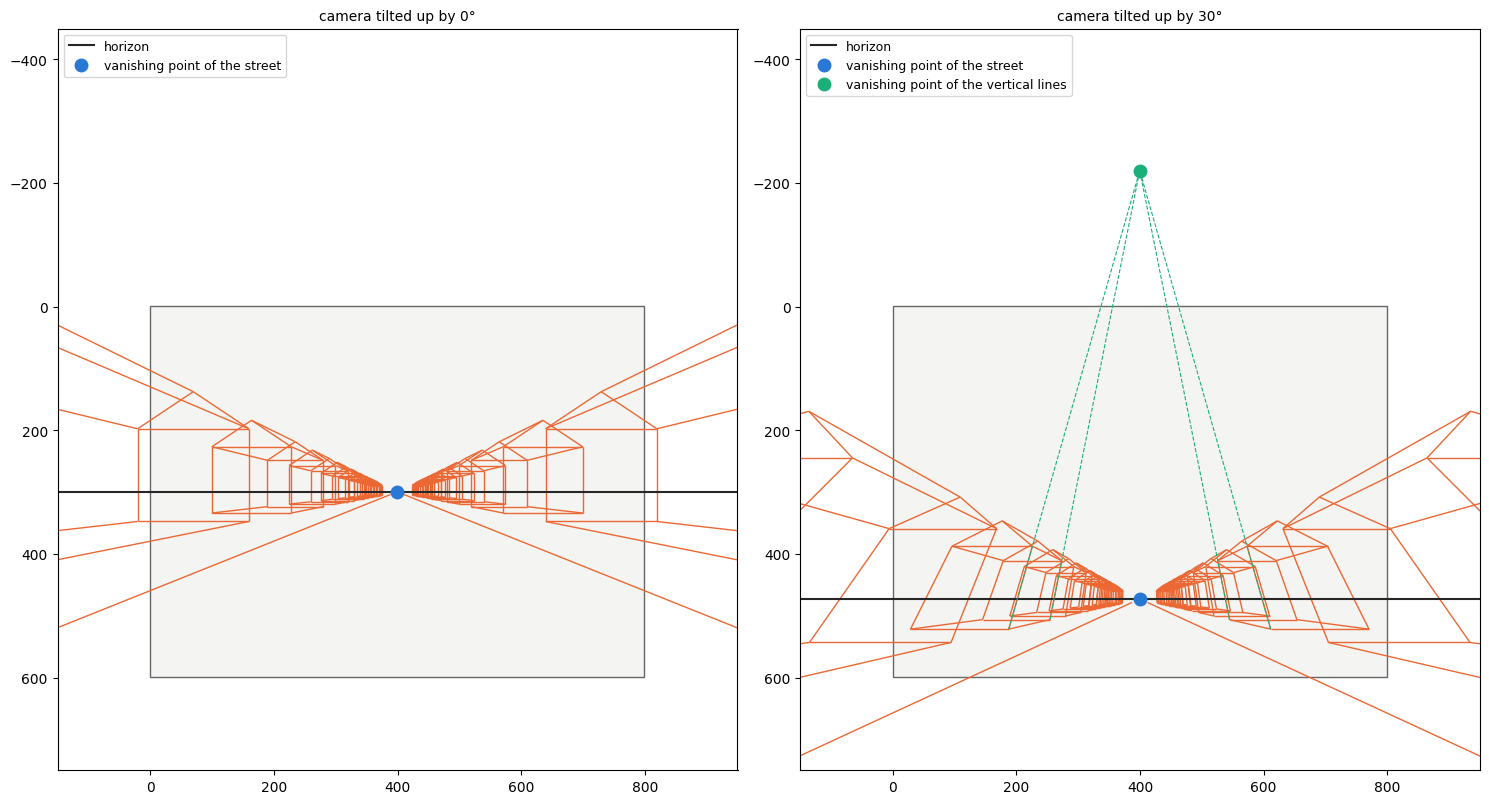

In [ ]:
street = np.concatenate([house(-14, y, 6, 6, 5, 2) for y in range(4, 100, 10)] +      # houses on the left ...
                        [house(8, y, 6, 6, 5, 2) for y in range(4, 100, 10)] +        # ... and on the right
                        [np.array([[[-4, 0, 0], [-4, 110, 0]], [[4, 0, 0], [4, 110, 0]]], dtype=float)])  # road
size_street = (800, 600)
K_street = np.array([[300, 0, 399.5],
                     [0, 300, 299.5],
                     [0, 0, 1]])
eye = np.array([0, 0, 1.6])

fig, axes = plt.subplots(1, 2, figsize=(15, 8.5))
for ax, pitch in zip(axes, [0, 30]):
    p = np.deg2rad(pitch)
    R, t = look_at(eye, eye + [0, np.cos(p), np.sin(p)])         # look along the street, tilted up by `pitch`
    image_axes(ax, size_street, f'camera tilted up by {pitch}°')
    ax.add_collection(LineCollection(project_segments(projection_matrix(K_street, R, t), street),
                                     colors='#eb6834', linewidths=1))
    vp_street = K_street @ R @ [0, 1, 0]                         # vanishing point of the street direction
    vp_vertical = K_street @ R @ [0, 0, 1]                       # ... and of the vertical direction
    horizon = np.linalg.inv(K_street).T @ R @ [0, 0, 1]          # l = K^-T R n
    us = np.array([-200.0, 1000.0])
    ax.plot(us, -(horizon[0] * us + horizon[2]) / horizon[1], color='0.15', lw=1.5, label='horizon')
    ax.plot(*(vp_street[:2] / vp_street[2]), 'o', color='#2a78d6', ms=9, label='vanishing point of the street')
    if abs(vp_vertical[2]) > 1e-9:
        vp = vp_vertical[:2] / vp_vertical[2]
        ax.plot(*vp, 'o', color='#1baf7a', ms=9, label='vanishing point of the vertical lines')
        corners = [[x0, y0, 0] for x0 in (-8, 8) for y0 in (14, 20)]   # vertical edges of the houses facing the street
        feet, _ = project_points(projection_matrix(K_street, R, t), corners)
        for foot in feet:                                                # extend them upwards
            ax.plot([foot[0], vp[0]], [foot[1], vp[1]], color='#1baf7a', lw=0.8, ls='--')
        print(f'tilted by {pitch}°: vertical vanishing point at {vp}')
    else:
        print(f'tilted by {pitch}°: the vertical vanishing point is at infinity, third coordinate {vp_vertical[2]}')
    print(f'tilted by {pitch}°: street vanishing point at {vp_street[:2] / vp_street[2]}, '
          f'horizon at v = {-horizon[2] / horizon[1]:.1f}')
    ax.set_xlim(-150, 950)
    ax.set_ylim(750, -450)
    ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

- Looking horizontally, the vanishing point of the street is the principal point, the horizon is the horizontal
  line through it, and vertical lines stay parallel ($\mathbf{r}_3$ is perpendicular to the vertical direction).
- Tilting the camera upwards moves the horizon **down** in the image (to $v = c_y + f \tan 30^\circ$), and the vertical
  edges of the houses now converge to a third vanishing point above the image. This is why buildings seem to lean
  backwards when they are photographed from the ground with the camera tilted up.

### 7.2 Focal length vs. distance
How large an object appears depends on $f / Z_c$. We can make it larger by moving closer (smaller $Z_c$) or by zooming
in (larger $f$), but the two are **not** the same:

- Changing $f$ (with the principal point fixed) only scales the image about the principal point: the new image is
  the old one transformed by the homography $K' K^{-1}$. Zooming in is the same as cropping and enlarging, and the
  relative sizes of near and far objects do not change.
- Moving the camera changes the depths by different factors: walking 6 units towards an object 12 units away
  halves its depth, while the depth of an object 100 units away hardly changes. **The perspective (how much larger
  near objects appear than far ones, and how quickly parallel lines converge) depends only on the position of the
  camera.**

The *dolly zoom* (or "Vertigo effect", after Hitchcock's film) changes both at the same time, keeping the ratio
of $f$ and the distance constant. The orange house keeps its size, while the street behind it changes completely:

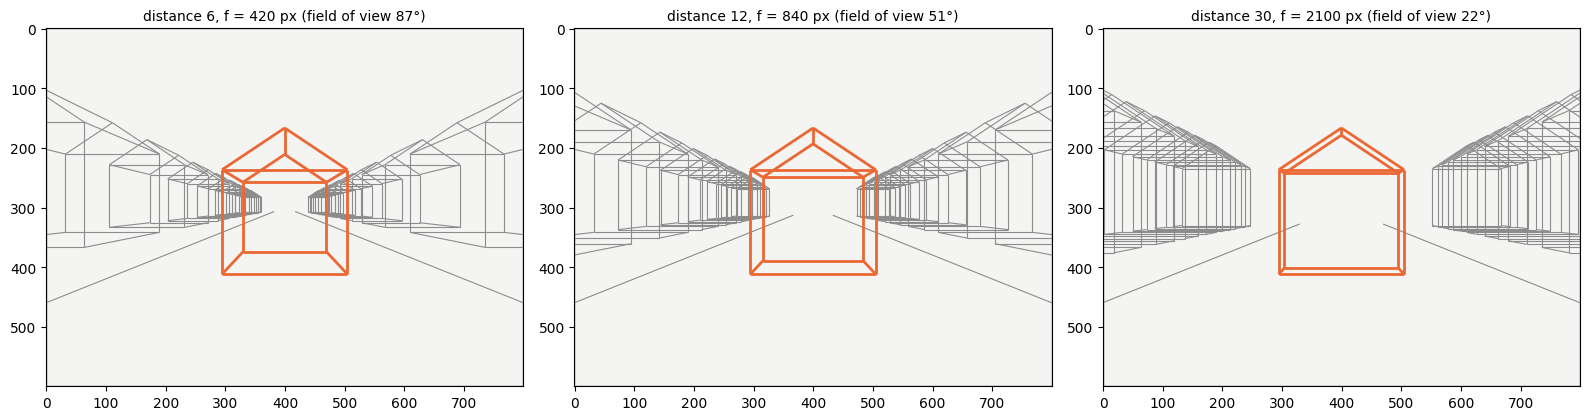

In [ ]:
subject = house(-1.5, 20, 3, 3, 2.5, 1.0)              # a small orange house in the middle of the road at y = 20
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, distance in zip(axes, [6, 12, 30]):
    f = 70 * distance                                    # f / distance is constant
    K = np.array([[f, 0, 399.5], [0, f, 299.5], [0, 0, 1]])
    eye = np.array([0, 20 - distance, 1.6])
    R, t = look_at(eye, eye + [0, 1, 0])
    P = projection_matrix(K, R, t)
    fov = np.degrees(2 * np.arctan(size_street[0] / (2 * f)))
    image_axes(ax, size_street, f'distance {distance}, f = {f} px (field of view {fov:.0f}°)')
    ax.add_collection(LineCollection(project_segments(P, street), colors='0.55', linewidths=0.8))
    ax.add_collection(LineCollection(project_segments(P, subject), colors='#eb6834', linewidths=2))
plt.tight_layout()
plt.show()

With the wide-angle lens (left), the camera is close to the orange house, and the houses along the street shrink
quickly with distance. With the telephoto lens (right), the camera is far away, the depths of all houses are of
similar magnitude, and the street looks compressed. The front face of the orange house has the same size in all
three images, but its back face (3 units farther) does not.

---

## 8. A Real Camera: Projecting a LiDAR Scan into a Photo

Now a real camera. Our data was recorded on the ELTE campus by a LiDAR and a camera mounted next to each other:

- `elte_lidar.xyz`: one scan of a rotating LiDAR, one 3D point per line, in meters, in the LiDAR's own coordinate
  system ($Z$ up, the sensor at the origin). This will be our **world coordinate system**. The LiDAR has 16 laser
  beams at elevation angles $-15^\circ, -13^\circ, \dots, +15^\circ$ that rotate around the vertical axis, so the scan
  consists of 16 rings. Directions without a return (e.g. towards the sky) are stored as $(0, 0, 0)$, and we remove
  them.
- `elte_image.jpg`: a photo taken at the same time by the camera.
- `calib_data.pkl`: the result of the **camera-LiDAR calibration**: the intrinsic parameters `(fx, fy, cx, cy)` and the
  extrinsic parameters `R` and `t`, in the OpenCV convention $\mathbf{X}_c = R\,\mathbf{X}_{lidar} + \mathbf{t}$.

In [ ]:
with open(os.path.join(DATA_DIR, 'calib_data.pkl'), 'rb') as file:
    calib = pickle.load(file)                  # unpickling can run code: only load pickles from sources you trust
fx, fy, cx, cy = calib['intrinsics']
K_cam = np.array([[fx, 0, cx],
                  [0, fy, cy],
                  [0, 0, 1]])
R_cam, t_cam = calib['R'], calib['t']
H_photo, W_photo = photo.shape[:2]

X_all = np.loadtxt(os.path.join(DATA_DIR, 'elte_lidar.xyz'))
X_lidar = X_all[np.any(X_all != 0, axis=1)]                 # drop the (0, 0, 0) entries: no return
print(f'LiDAR points: {len(X_all)}, without the empty returns: {len(X_lidar)}')

print('K =\n', K_cam)
print('R =\n', R_cam)
print('t =', t_cam)
print(f'det R = {np.linalg.det(R_cam):.5f}, max |R^T R - I| = {np.abs(R_cam.T @ R_cam - np.eye(3)).max():.1e}')

C_cam = -R_cam.T @ t_cam
view_dir = R_cam[2]
print('camera center in LiDAR coordinates: C = -R^T t =', C_cam)
print('viewing direction r3 =', view_dir,
      f'({np.degrees(np.arcsin(view_dir[2])):.1f}° above the horizontal plane)')
print(f'field of view: {np.degrees(2 * np.arctan(W_photo / (2 * fx))):.1f} x {np.degrees(2 * np.arctan(H_photo / (2 * fy))):.1f} degrees')

LiDAR points: 14976, without the empty returns: 11245
K =
 [[625.   0. 480.]
 [  0. 625. 300.]
 [  0.   0.   1.]]
R =
 [[ 0.923   0.3848  0.0018]
 [-0.0066  0.0203 -0.9998]
 [-0.3847  0.9228  0.0213]]
t = [-0.0397  0.1842 -0.0944]
det R = 1.00003, max |R^T R - I| = 6.6e-05
camera center in LiDAR coordinates: C = -R^T t = [0.0015 0.0986 0.1862]
viewing direction r3 = [-0.3847  0.9228  0.0213] (1.2° above the horizontal plane)
field of view: 75.0 x 51.3 degrees


The camera is about 10 cm from the LiDAR along its $Y$ axis and 19 cm above it, and it looks practically horizontally
(the $Z$ component of $\mathbf{r}_3$ is tiny). $R$ was stored with 4 decimals, so it is a rotation matrix only up to
about $10^{-4}$, which is more than enough here.

### 8.1 The scan in the photo
We project every LiDAR point with $P = K[R \mid \mathbf{t}]$, and keep the points that are in front of the camera
($Z_c > 0$) and whose nearest pixel, `(floor(u + 0.5), floor(v + 0.5))`, lies inside the image. The points are
colored by their depth. The photo is shown in gray, so that the colors of the points stand out.

in front of the camera: 6128 points, inside the photo: 2503 points
depth of the points inside the photo: 4.0 m to 77.0 m


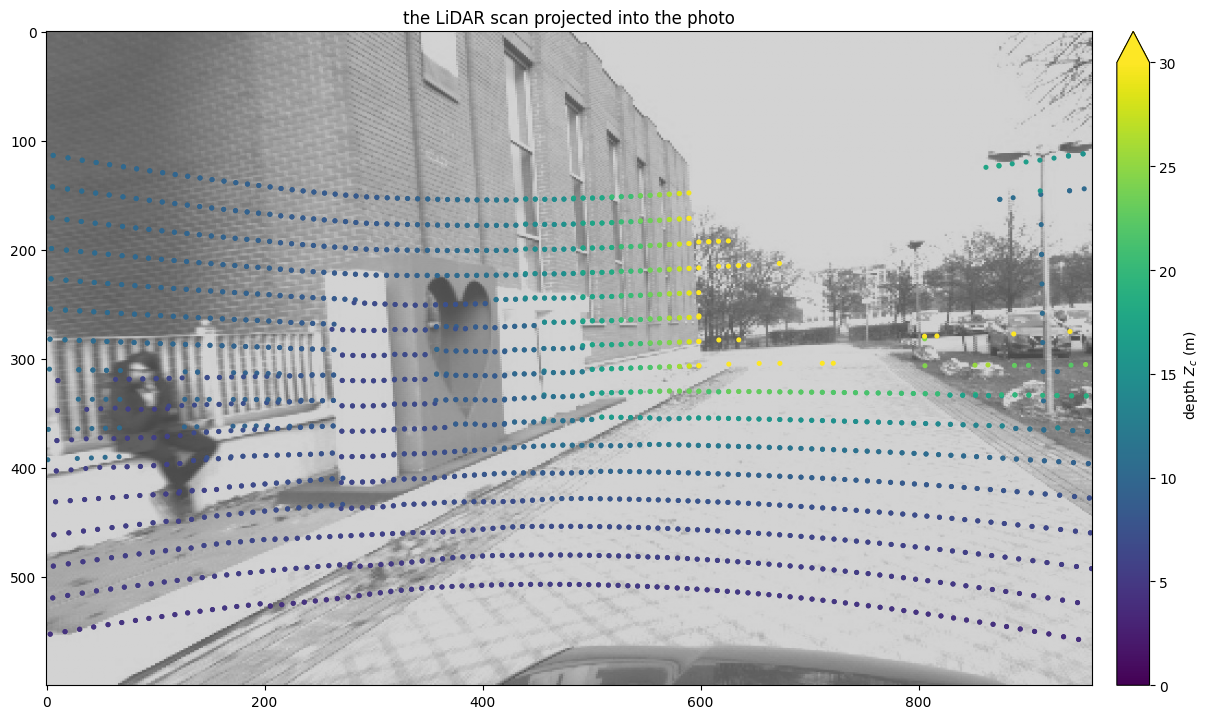

In [ ]:
P_cam = projection_matrix(K_cam, R_cam, t_cam)
uv_lidar, depth_lidar = project_points(P_cam, X_lidar)
u_pix = np.floor(uv_lidar[:, 0] + 0.5)                      # the nearest pixel
v_pix = np.floor(uv_lidar[:, 1] + 0.5)
in_photo = (depth_lidar > 0) & (u_pix >= 0) & (u_pix < W_photo) & (v_pix >= 0) & (v_pix < H_photo)
print(f'in front of the camera: {np.sum(depth_lidar > 0)} points, inside the photo: {np.sum(in_photo)} points')
print(f'depth of the points inside the photo: {depth_lidar[in_photo].min():.1f} m to {depth_lidar[in_photo].max():.1f} m')

gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
fig, ax = plt.subplots(figsize=(13, 7.3))
ax.imshow(gray, cmap='gray', vmin=-120, vmax=330)           # a washed-out gray version of the photo
points = ax.scatter(uv_lidar[in_photo, 0], uv_lidar[in_photo, 1], c=depth_lidar[in_photo],
                    cmap='viridis', vmin=0, vmax=30, s=7)
fig.colorbar(points, ax=ax, label='depth $Z_c$ (m)', fraction=0.03, pad=0.02, extend='max')
ax.set_xlim(-0.5, W_photo - 0.5)
ax.set_ylim(H_photo - 0.5, -0.5)
ax.set_title('the LiDAR scan projected into the photo')
plt.tight_layout()
plt.show()

The scan lines fit the scene: they run along the wall of the building, change depth abruptly at the edges of the sign,
and get farther along the street. This is how a camera-LiDAR calibration is usually checked by eye. (Each ring of the
LiDAR is a cone around the vertical axis. It cuts the ground in a circle, and the images of these circles are the
curves on the pavement.)

### 8.2 Coloring the scan
The other way round: every LiDAR point that is seen by the camera takes the color of its pixel, and the remaining
points (outside the field of view of the camera) stay gray. This is how colored point clouds are made from LiDAR
scans.

One subtlety: a LiDAR point that is hidden from the camera by a nearer object still lands on a pixel, and takes the
color of the object in front of it. Since the camera is only about 20 cm from the LiDAR, this happens only along
depth edges, e.g. at the border of the sign. A careful implementation checks the visibility with a depth buffer (the
smallest depth seen at every pixel, see Section 9) and colors only the points that are not behind it.

In [ ]:
UNSEEN_GRAY = 110
colors_lidar = np.full((len(X_lidar), 3), UNSEEN_GRAY, dtype=np.uint8)          # BGR, like the photo
colors_lidar[in_photo] = photo[v_pix[in_photo].astype(int), u_pix[in_photo].astype(int)]
print(f'{np.mean(in_photo):.1%} of the points got a color from the photo')

22.3% of the points got a color from the photo


---
## 9. A Virtual Camera: Viewing the Colored Scan from Anywhere

The projection formula does not care whether the camera exists. With our own $K$, $R$ and $\mathbf{t}$ we can look at
the colored scan from any viewpoint. To turn the projected points into an image we need:

- the **depth test**: only the points in front of the camera ($Z_c > 0$) are drawn;
- **visibility**: several points may fall on the same pixel, and the nearest one must win. We use the simplest
  solution, the **painter's algorithm**: the points are drawn from the farthest to the nearest, so the nearer points
  are painted over the farther ones. (A *depth buffer*, or z-buffer, gets the same result without sorting: it
  stores the smallest depth at every pixel. This is what graphics cards do.)
- since the scan is sparse, every point is drawn as a small filled disc of radius $r$ pixels, with `cv2.circle`.

In [ ]:
BEHIND_BGR = np.array([214, 120, 42], dtype=np.uint8)       # blue, for the points behind the camera


def render_points(X, colors, K, R, t, size, radius=2, show_behind=False):
    """Render the points X (N, 3) with BGR colors (N, 3) from the camera (K, R, t) into a black image.

    size: (width, height). Every point is drawn as a filled circle with cv2.circle, from the farthest point to the
    nearest, so where points overlap, the nearest one is on top (painter's algorithm).
    show_behind: also draw the points behind the camera (in blue), to see what the depth test is for.
    """
    w, h = size
    uv, depth = project_points(projection_matrix(K, R, t), X)
    colors = np.asarray(colors, dtype=np.uint8)
    if show_behind:
        colors = np.where((depth < 0)[:, None], BEHIND_BGR, colors)
        depth = np.abs(depth)
    u, v = np.floor(uv[:, 0] + 0.5), np.floor(uv[:, 1] + 0.5)      # the nearest pixel
    keep = (depth > 0) & (u >= -radius) & (u < w + radius) & (v >= -radius) & (v < h + radius)

    image = np.zeros((h, w, 3), dtype=np.uint8)
    for i in np.argsort(-depth):                                  # from the farthest point to the nearest
        if keep[i]:
            cv2.circle(image, (int(u[i]), int(v[i])), radius, colors[i].tolist(), thickness=-1)
    return image

### 9.1 Back in the real camera
First we put the virtual camera exactly where the real one was, with $K$, $R$ and $\mathbf{t}$ from the calibration.
The rendering is a sparse copy of the photo. Then we switch off the depth test (`show_behind=True`): the points
behind the camera, drawn in blue, are projected through the camera center onto the same image, and form an
upside-down image of everything behind the camera. Whenever a camera is inside a scene, the depth test is
essential.

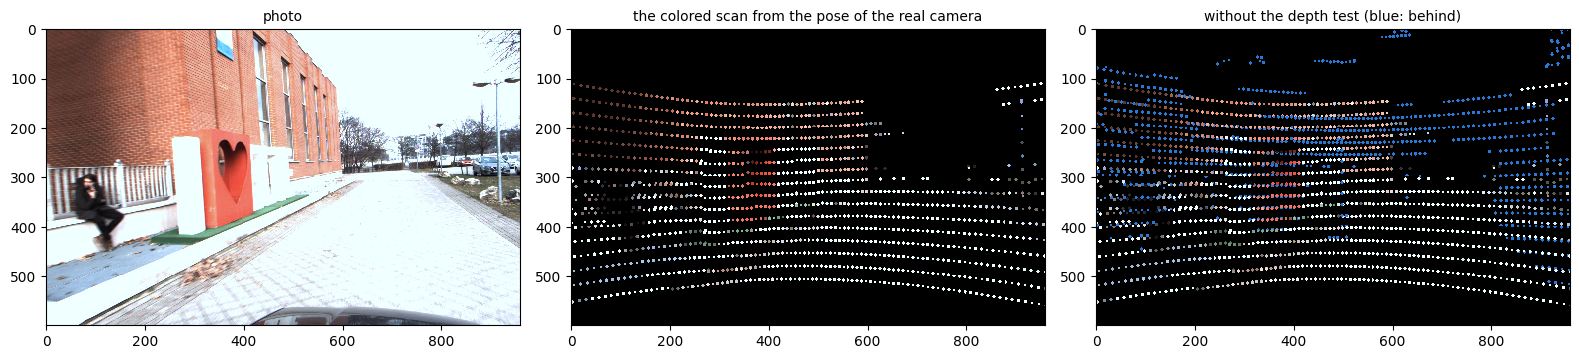

In [ ]:
size_photo = (W_photo, H_photo)
render_real = render_points(X_lidar, colors_lidar, K_cam, R_cam, t_cam, size_photo, radius=3)
render_ghost = render_points(X_lidar, colors_lidar, K_cam, R_cam, t_cam, size_photo, radius=3, show_behind=True)
show_images([photo, render_real, render_ghost],
            ['photo', 'the colored scan from the pose of the real camera', 'without the depth test (blue: behind)'],
            cols=3, size=5.3)

### 9.2 New viewpoints
Now cameras that never existed: a bird's-eye view from 50 m above the scan, and an orbit camera behind and above
the LiDAR. In both views we also draw the viewing pyramid of the real camera (cut at a depth of 20 m), to see which
part of the scan got its colors from the photo.

Looking straight down, the viewing direction is parallel to the world's up direction, and `look_at` cannot compute
$\mathbf{r}_1$. So for the bird's-eye view we choose $\mathbf{up} = Y_w$: the $Y$ axis of the LiDAR points upwards in the image,
like north on a map.

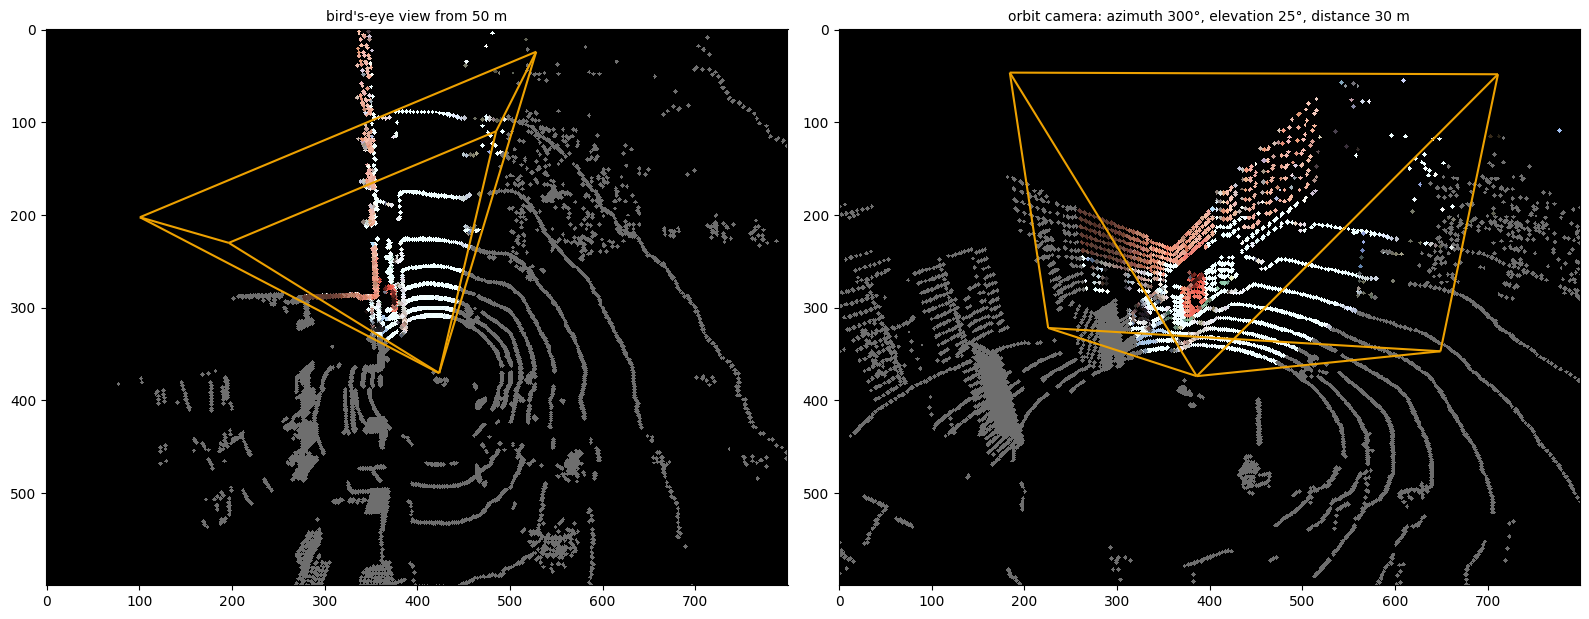

In [ ]:
size_virtual = (800, 600)
K_virtual = np.array([[600, 0, 399.5],
                      [0, 600, 299.5],
                      [0, 0, 1]])
target_scene = np.array([-4.0, 8.0, -1.0])                  # a point of the scene, near the sign
real_frustum = camera_frustum(K_cam, R_cam, t_cam, size_photo, depth=20)

views = {'bird\'s-eye view from 50 m': look_at([-2, 6, 50], [-2, 6, 0], up=(0, 1, 0)),
         'orbit camera: azimuth 300°, elevation 25°, distance 30 m': orbit_camera(300, 25, 30, target_scene)}

fig, axes = plt.subplots(1, 2, figsize=(16, 6.3))
for ax, (title, (R, t)) in zip(axes, views.items()):
    ax.imshow(to_rgb(render_points(X_lidar, colors_lidar, K_virtual, R, t, size_virtual)), interpolation='nearest')
    ax.add_collection(LineCollection(project_segments(projection_matrix(K_virtual, R, t), real_frustum),
                                     colors='#eda100', linewidths=1.5))
    ax.set_xlim(-0.5, size_virtual[0] - 0.5)
    ax.set_ylim(size_virtual[1] - 0.5, -0.5)
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

In the bird's-eye view, the rings of the LiDAR are circles around the sensor, the wall of the building is a straight
line of red points, and the colored part of the scan lies inside the viewing pyramid of the real camera (yellow,
which of course continues beyond the 20 m where we cut it).

### 9.3 Try it yourself (interactive)
If `ipywidgets` is available (it is in Colab), the sliders move the orbit camera around the scene and change its
focal length. Try a small distance with `show_behind` switched on, and compare moving the camera with changing $f$.

In [ ]:
try:
    from ipywidgets import interact, FloatSlider, Checkbox
except ImportError:
    interact = None
    print('ipywidgets is not installed (pip install ipywidgets), skipping the interactive demo.')

if interact is not None:
    def explore_virtual_camera(azimuth=300.0, elevation=25.0, distance=30.0, focal_length=600.0, show_behind=False):
        K = np.array([[focal_length, 0, 399.5], [0, focal_length, 299.5], [0, 0, 1]])
        R, t = orbit_camera(azimuth, elevation, distance, target_scene)
        image = render_points(X_lidar, colors_lidar, K, R, t, size_virtual, show_behind=show_behind)
        fig, ax = plt.subplots(figsize=(9, 6.9))
        ax.imshow(to_rgb(image), interpolation='nearest')
        ax.add_collection(LineCollection(project_segments(projection_matrix(K, R, t), real_frustum),
                                         colors='#eda100', linewidths=1.5))
        ax.set_xlim(-0.5, size_virtual[0] - 0.5)
        ax.set_ylim(size_virtual[1] - 0.5, -0.5)
        ax.set_title(f'camera center: {np.round(-R.T @ t, 1)}', fontsize=10)
        plt.show()

    interact(explore_virtual_camera,
             azimuth=FloatSlider(min=0, max=360, step=5, value=300),
             elevation=FloatSlider(min=-10, max=89, step=1, value=25),
             distance=FloatSlider(min=2, max=100, step=1, value=30),
             focal_length=FloatSlider(min=150, max=2000, step=10, value=600),
             show_behind=Checkbox(value=False))

interactive(children=(FloatSlider(value=300.0, description='azimuth', max=360.0, step=5.0), FloatSlider(value=…

---
## 10. Summary

| | parameters | DOF | maps |
|---|---|---|---|
| extrinsic $[R \mid \mathbf{t}]$ | rotation $R$ (e.g. as a rotation vector) and translation $\mathbf{t} = -R\,\mathbf{C}$ | 3 + 3 | world $\to$ camera coordinates |
| intrinsic $K$ | $f_x = f k_u$, $f_y = f k_v$, principal point $(c_x, c_y)$, (skew $s$) | 4 (5) | camera coordinates $\to$ pixels |
| projection $P = K[R \mid \mathbf{t}]$ | all of the above, up to scale | 11 | world $\to$ pixels |

Key takeaways:
- The pinhole camera divides by the depth: $u = f_x X_c / Z_c + c_x$, $v = f_y Y_c / Z_c + c_y$. In homogeneous coordinates
  this is linear, $\lambda (u, v, 1)^\top = P\,(\mathbf{X}_w, 1)^\top$, and the third coordinate $\lambda$ is the **depth**.
- Image size is inversely proportional to depth, and depth itself is lost: all points of a ray have the same image.
  A pixel only determines the direction of its ray, $K^{-1}(u, v, 1)^\top$.
- $\mathbf{X}_c = R\mathbf{X}_w + \mathbf{t} = R(\mathbf{X}_w - \mathbf{C})$: $\mathbf{t}$ is **not** the camera position, $\mathbf{C} = -R^\top\mathbf{t}$ is. The rows
  of $R$ are the camera axes in world coordinates. The camera center spans the null space of $P$.
- Points behind the camera are projected too (mirrored through the center), so **always check $Z_c > 0$**. Neither the
  formula nor `cv2.projectPoints` does this for you.
- Parallel lines meet at the vanishing point $KR\,\mathbf{d}$, which depends only on the orientation of the camera; the
  horizon is $K^{-\top}R\,\mathbf{n}$. Changing $f$ only zooms the image, the perspective is set by the camera position.
- OpenCV: `cv2.projectPoints` (rotation vector, `distCoeffs`), `cv2.Rodrigues`, `cv2.decomposeProjectionMatrix` (returns
  the homogeneous camera **center**), `cv2.calibrationMatrixValues` (field of view), `cv2.undistortPoints` (normalized
  coordinates).

### Exercises
1. **The ground plane and the horizon.** Fit a plane to the LiDAR points on the pavement, e.g. to the points of
   Section 8.1 that fall into the region $v > 400$, $450 < u < 850$ of the photo (with the centroid and the SVD, as for
   lines in the line fitting class). Compute the horizon $\mathbf{l} = K^{-\top} R\,\mathbf{n}$ both for the normal of this plane
   and for $\mathbf{n} = (0, 0, 1)$, and draw them on the photo. Which one passes through the point where the edges of the
   pavement meet? What does this tell you about the $Z$ axis of the LiDAR?
2. **Measuring with a single camera.** Pick a pixel on the pavement, back-project its ray,
   $\mathbf{X}_w = \mathbf{C} + \lambda R^\top K^{-1}(u, v, 1)^\top$, and intersect it with the fitted plane. Compare the depth $\lambda$
   with the depths of the nearby LiDAR points in Section 8.1. Why is the error larger for pixels close to the horizon?
3. **Decomposing $P$ by hand.** The left $3 \times 3$ block of $P$ is $M = KR$: an upper triangular matrix times a
   rotation. Recover $K$ and $R$ with an RQ decomposition (hint: apply `np.linalg.qr` to the flipped and transposed
   matrix, then fix the signs so that the diagonal of $K$ is positive), then $\mathbf{t} = K^{-1}\mathbf{p}_4$ from the last
   column. Compare with `cv2.decomposeProjectionMatrix` and with the calibration data.
4. **Resizing changes $K$.** Downscale the photo by a factor of 2 with `cv2.resize`. How do $f_x, f_y, c_x, c_y$ change?
   (Careful with the pixel centers: $u' = (u + 0.5)/2 - 0.5$.) Check your answer by projecting the LiDAR scan into the
   small image.